In [1]:
import zarr
import networkx as nx
import geff # or however you've been loading geff — adjust to your setup

z = zarr.open(r"biohub-cell-tracking-during-development\train\6bba_0c7fa718.zarr", mode="r")
z =  z["0"]
print("zarr shape:", z.shape, "dtype:", z.dtype)
print("zarr attrs:", dict(z.attrs))  # look for voxel_size / scale / units here

g, meta = geff.read(r"biohub-cell-tracking-during-development\train\6bba_0c7fa718.geff")
sample_node = list(g.nodes(data=True))[0]
print("sample geff node:", sample_node)
print("geff graph-level metadata:", meta)  # look for voxel_size/scale/units here too

zarr shape: (100, 64, 256, 256) dtype: uint16
zarr attrs: {}
sample geff node: (1000002, {'z': 44, 'x': 158, 'y': 152, 't': 0})
geff graph-level metadata: geff_version='1.1' directed=True axes=[Axis(name='t', type='time', unit=None, min=0.0, max=99.0, scale=1.0, scaled_unit=None, offset=None), Axis(name='z', type='space', unit=None, min=17.0, max=62.0, scale=1.625, scaled_unit=None, offset=None), Axis(name='y', type='space', unit=None, min=2.0, max=253.0, scale=0.40625, scaled_unit=None, offset=None), Axis(name='x', type='space', unit=None, min=4.0, max=252.0, scale=0.40625, scaled_unit=None, offset=None)] node_props_metadata={'t': PropMetadata(identifier='t', dtype='int64', varlength=False, unit=None, name=None, description=None), 'z': PropMetadata(identifier='z', dtype='int64', varlength=False, unit=None, name=None, description=None), 'y': PropMetadata(identifier='y', dtype='int64', varlength=False, unit=None, name=None, description=None), 'x': PropMetadata(identifier='x', dtype='int

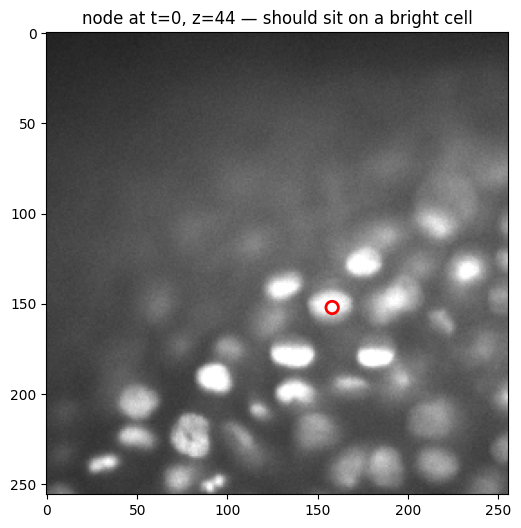

In [2]:
import matplotlib.pyplot as plt

t0, z0, y0, x0 = sample_node[1]['t'], sample_node[1]['z'], sample_node[1]['y'], sample_node[1]['x']

img_slice = z[t0, z0]  # single Z-plane at this timepoint — cheap, no full volume load

fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(img_slice, cmap='gray', vmin=0, vmax=img_slice.max()*0.6)
ax.scatter([x0], [y0], s=80, facecolors='none', edgecolors='red', linewidths=2)
ax.set_title(f"node at t={t0}, z={z0} — should sit on a bright cell")
plt.show()

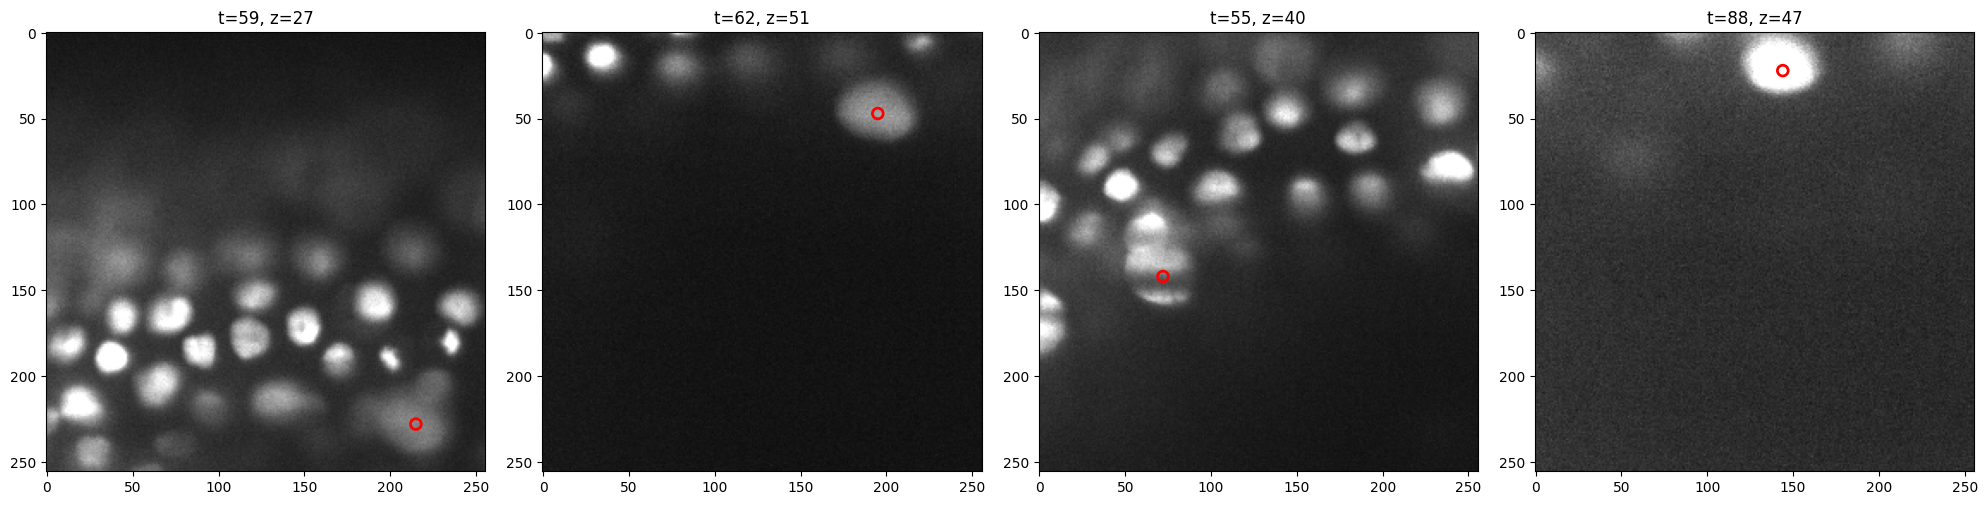

In [3]:
import random

# grab a handful of random nodes across different t and z ranges
nodes = list(g.nodes(data=True))
sample = random.sample(nodes, 4)

fig, axes = plt.subplots(1, 4, figsize=(20,5))
for ax, (nid, attrs) in zip(axes, sample):
    t, zc, y, x = attrs['t'], attrs['z'], attrs['y'], attrs['x']
    img_slice = z[t, zc]
    ax.imshow(img_slice, cmap='gray', vmin=0, vmax=img_slice.max()*0.6)
    ax.scatter([x], [y], s=60, facecolors='none', edgecolors='red', linewidths=2)
    ax.set_title(f"t={t}, z={zc}")
plt.tight_layout()
plt.show()

In [4]:
import numpy as np

def extract_patch(zarr_arr, t, z, y, x, patch_size=(16, 64, 64)):
    """Extract a (z,y,x) patch from zarr_arr at timepoint t, centered on (z,y,x).
    Returns the patch and a flag for whether it was clipped at a boundary."""
    pz, py, px = patch_size
    T, Z, Y, X = zarr_arr.shape

    z0, z1 = z - pz // 2, z + pz // 2
    y0, y1 = y - py // 2, y + py // 2
    x0, x1 = x - px // 2, x + px // 2

    clipped = z0 < 0 or z1 > Z or y0 < 0 or y1 > Y or x0 < 0 or x1 > X

    # clamp to valid range, then pad to preserve exact patch_size
    cz0, cz1 = max(z0, 0), min(z1, Z)
    cy0, cy1 = max(y0, 0), min(y1, Y)
    cx0, cx1 = max(x0, 0), min(x1, X)

    raw = zarr_arr[t, cz0:cz1, cy0:cy1, cx0:cx1]

    pad = ((max(0, -z0), max(0, z1 - Z)),
           (max(0, -y0), max(0, y1 - Y)),
           (max(0, -x0), max(0, x1 - X)))
    patch = np.pad(raw, pad, mode='constant', constant_values=0)

    return patch, clipped

interior patch shape: (16, 64, 64) clipped: False


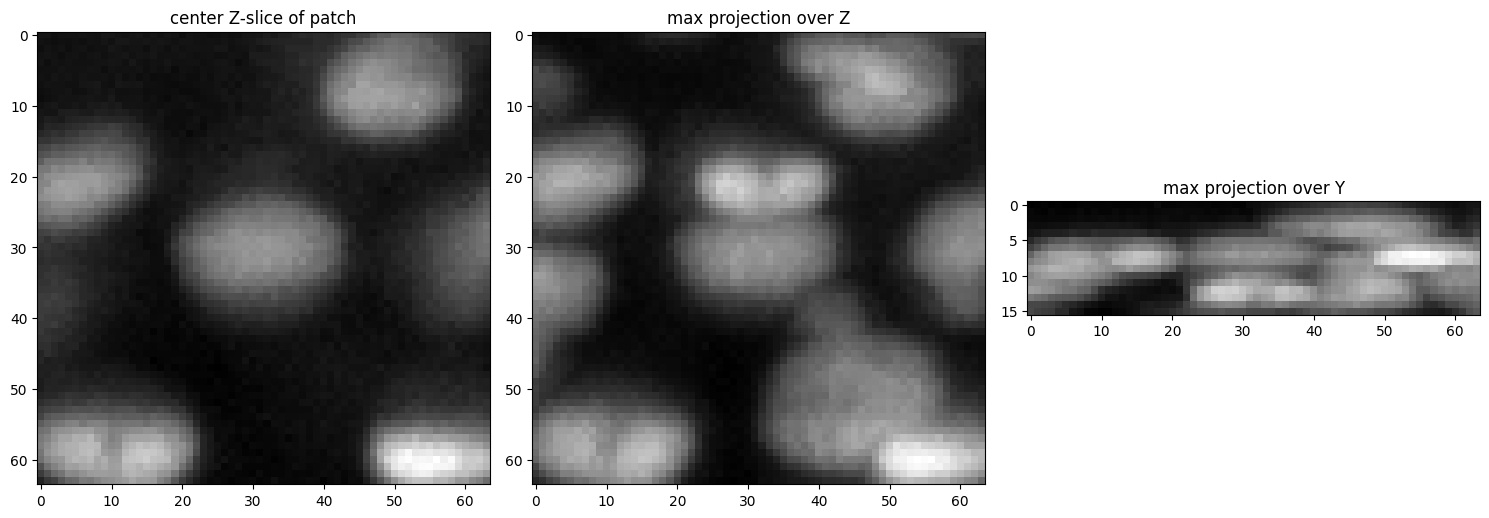

In [5]:
# interior node — should have clipped=False
patch, clipped = extract_patch(z, t0, z0, y0, x0, patch_size=(16, 64, 64))
print("interior patch shape:", patch.shape, "clipped:", clipped)

fig, axes = plt.subplots(1, 3, figsize=(15,5))
axes[0].imshow(patch[patch.shape[0]//2], cmap='gray')
axes[0].set_title("center Z-slice of patch")
axes[1].imshow(patch.max(axis=0), cmap='gray')
axes[1].set_title("max projection over Z")
axes[2].imshow(patch.max(axis=1), cmap='gray')
axes[2].set_title("max projection over Y")
plt.tight_layout()
plt.show()

In [6]:
import napari

# viewer.add_image scale param = physical size per voxel, in (z,y,x) order
# this is what makes the render look like a real cell instead of a stretched blob
voxel_scale = (1.625, 0.40625, 0.40625)

viewer = napari.Viewer(ndisplay=3)
viewer.add_image(patch, scale=voxel_scale, rendering='mip', name='patch')

# mark the center of the patch — where the node should be
pz, py, px = patch.shape
center_point = [[pz // 2, py // 2, px // 2]]
viewer.add_points(center_point, scale=voxel_scale, size=3, face_color='red', name='node center')

napari.run()

In [7]:
def downsample_isotropic(patch, node_coords, factor=4):
    """Downsample Y,X by `factor` to match Z's coarser physical spacing.
    node_coords: (z, y, x) position within the patch, in original voxel units."""
    # simple strided subsampling — cheap, matches what the baseline does at read-time
    ds_patch = patch[:, ::factor, ::factor]

    z, y, x = node_coords
    ds_coords = (z, y / factor, x / factor)

    return ds_patch, ds_coords

ds_patch, ds_node = downsample_isotropic(patch, (pz//2, py//2, px//2), factor=4)
print("original patch shape:", patch.shape)
print("downsampled patch shape:", ds_patch.shape)
print("node position, downsampled:", ds_node)

original patch shape: (16, 64, 64)
downsampled patch shape: (16, 16, 16)
node position, downsampled: (8, 8.0, 8.0)


In [8]:
viewer2 = napari.Viewer(ndisplay=3)
viewer2.add_image(ds_patch, rendering='mip', name='downsampled patch')  # no scale needed — already isotropic
viewer2.add_points([[ds_node[0], ds_node[1], ds_node[2]]], size=1.5, face_color='red')
napari.run()

In [9]:
def downsample_isotropic_maxpool(patch, node_coords, factor=4):
    """Max-pool Y,X by `factor`, leave Z untouched.
    node_coords: (z, y, x) position within the patch, original voxel units."""
    Z, Y, X = patch.shape
    assert Y % factor == 0 and X % factor == 0, "patch Y/X must be divisible by factor"

    # reshape splits each axis into (n_blocks, factor), then max over the factor dim
    ds_patch = patch.reshape(Z, Y // factor, factor, X // factor, factor).min(axis=(2, 4))

    z, y, x = node_coords
    ds_coords = (z, y / factor, x / factor)

    return ds_patch, ds_coords

ds_patch_mp, ds_node_mp = downsample_isotropic_maxpool(patch, (pz//2, py//2, px//2), factor=4)
print("maxpool downsampled shape:", ds_patch_mp.shape)

maxpool downsampled shape: (16, 16, 16)


In [10]:
viewer3 =  napari.Viewer(ndisplay=3)
viewer3.add_image(ds_patch_mp, rendering='mip', name='maxpool downsampled patch')  # no scale needed — already isotropic
viewer3.add_points([[ds_node_mp[0], ds_node_mp[1], ds_node_mp[2]]], size=1.5, face_color='red', name='node center')
napari.run()

In [11]:
def make_heatmap_target(patch_shape, node_coords):
    """Hard one-hot detection target: 1 at the node's rounded voxel, 0 elsewhere."""
    target = np.zeros(patch_shape, dtype=np.float32)
    z, y, x = [int(round(c)) for c in node_coords]

    # clip in case rounding pushes it just out of bounds
    z = np.clip(z, 0, patch_shape[0]-1)
    y = np.clip(y, 0, patch_shape[1]-1)
    x = np.clip(x, 0, patch_shape[2]-1)

    target[z, y, x] = 1.0
    return target, (z, y, x)

target, snapped_coords = make_heatmap_target(ds_patch_mp.shape, ds_node_mp)
print("target sum (should be exactly 1.0):", target.sum())
print("snapped voxel:", snapped_coords)

target sum (should be exactly 1.0): 1.0
snapped voxel: (np.int64(8), np.int64(8), np.int64(8))


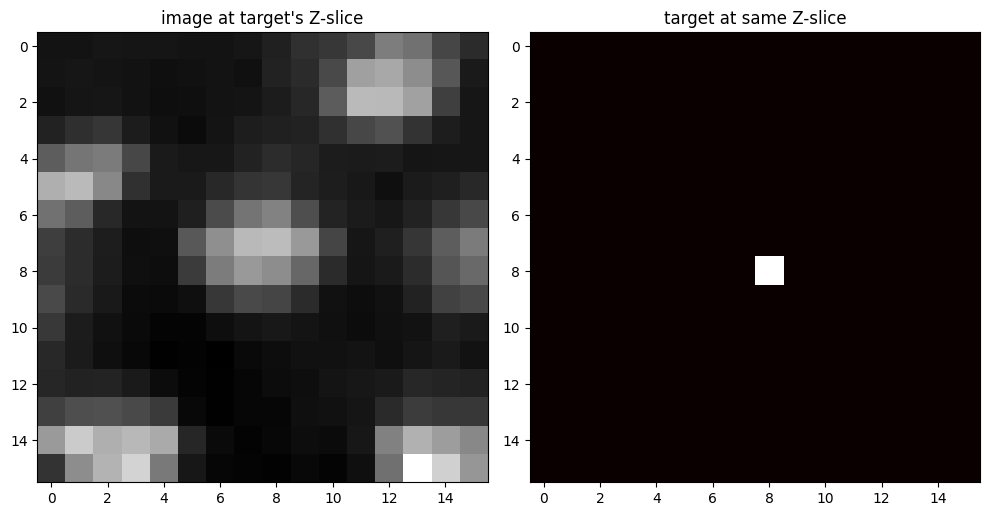

In [12]:
z_mid = snapped_coords[0]
fig, axes = plt.subplots(1, 2, figsize=(10,5))
axes[0].imshow(ds_patch_mp[z_mid], cmap='gray')
axes[0].set_title("image at target's Z-slice")
axes[1].imshow(target[z_mid], cmap='hot')
axes[1].set_title("target at same Z-slice")
plt.tight_layout()
plt.show()